# Deep Learning Models - NASA C-MAPSS

The baselines (Linear Regression, Random Forest) only see 4 summary numbers per sensor.
Here we train models that read the full 30-cycle window instead: a 1D-CNN, an LSTM and a GRU.
The models and the training loop are in `src/deep_models.py`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.features import CAP, prepare, split_engines, make_windows, last_windows
from src.deep_models import make_model, train, predict
from models.compare_baselines import nasa_score

## Step 1. Prepare the windows (FD001)

In [2]:
train_df, test_df, sensors = prepare("FD001")
tr, va = split_engines(train_df)

X_train, y_train = make_windows(tr, sensors)
X_val, y_val = make_windows(va, sensors)
X_test, y_test = last_windows(test_df, sensors)

print("train:", X_train.shape, " val:", X_val.shape, " test:", X_test.shape)

train: (13980, 30, 14)  val: (3751, 30, 14)  test: (100, 30, 14)


Each sample is 30 cycles x 14 sensors. The label is the RUL (capped at 125) at the last cycle of the window.
80% of the training engines are used to train, the other 20% decide when to stop training.

## Step 2. The three models

In [3]:
for name in ["CNN", "LSTM", "GRU"]:
    model = make_model(name, len(sensors))
    n_params = sum(p.numel() for p in model.parameters())
    print(name, "-", n_params, "parameters")
    print(model, "\n")

CNN - 135585 parameters
CNN(
  (conv): Sequential(
    (0): Conv1d(14, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): ReLU()
    (2): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (3): ReLU()
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.2, inplace=False)
    (2): Linear(in_features=1920, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
) 

LSTM - 55873 parameters
RNN(
  (rnn): LSTM(14, 64, num_layers=2, batch_first=True, dropout=0.2)
  (head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
) 

GRU - 42433 parameters
RNN(
  (rnn): GRU(14, 64, num_layers=2, batch_first=True, dropout=0.2)
  (head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
) 



- **CNN**: filters slide along the 30 cycles and detect local shapes, like a sensor starting to curve upwards.
- **LSTM**: reads the window one cycle at a time and keeps a memory, so it can tell slow drift from a sudden change.
- **GRU**: a simpler version of the LSTM with fewer parameters; often just as good.

All three end with a small fully connected layer that outputs one number: the RUL.

## Step 3. Train

Training uses MSE loss and the Adam optimizer. After each epoch we check the RMSE on the validation engines
and keep the best weights. If validation doesn't improve for 8 epochs, training stops (early stopping),
which prevents overfitting.

In [4]:
models = {}
for name in ["CNN", "LSTM", "GRU"]:
    print(name)
    torch.manual_seed(0)
    models[name] = train(make_model(name, len(sensors)), X_train, y_train, X_val, y_val, verbose=True)
    print()

CNN


epoch  1  val RMSE 27.77


epoch  2  val RMSE 23.03


epoch  3  val RMSE 21.54


epoch  4  val RMSE 17.88


epoch  5  val RMSE 16.54


... (70 outputs left out)

epoch 41  val RMSE 15.25


epoch 42  val RMSE 14.50


epoch 43  val RMSE 14.85


epoch 44  val RMSE 15.89



## Step 4. Evaluate on the test engines

In [5]:
y_capped = np.minimum(y_test, CAP)
preds = {name: predict(m, X_test) for name, m in models.items()}

for name, p in preds.items():
    rmse = np.sqrt(np.mean((p - y_capped) ** 2))
    print(f"{name:5s} RMSE {rmse:.2f}   NASA score {nasa_score(y_capped, p):.0f}")

CNN   RMSE 15.00   NASA score 453
LSTM  RMSE 15.32   NASA score 536
GRU   RMSE 14.55   NASA score 401


As with the baselines, test labels are capped at 125 (the training target) and each test engine is scored at its last cycle.

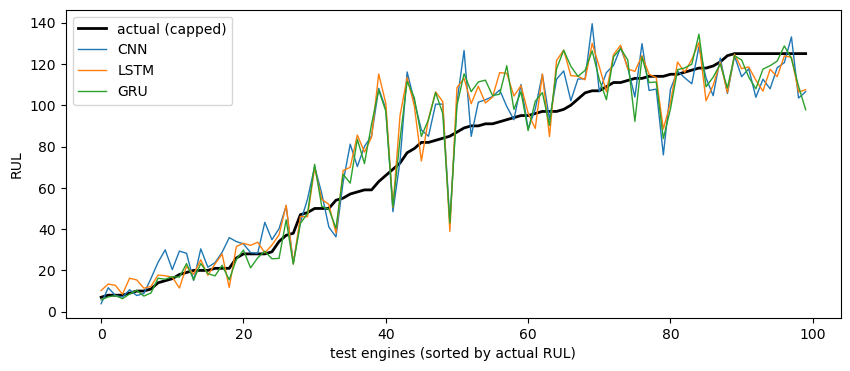

In [6]:
order = np.argsort(y_capped)
plt.figure(figsize=(10, 4))
plt.plot(y_capped[order], color="black", lw=2, label="actual (capped)")
for name, p in preds.items():
    plt.plot(p[order], lw=1, label=name)
plt.xlabel("test engines (sorted by actual RUL)")
plt.ylabel("RUL")
plt.legend()
plt.show()

## Step 5. All four subsets vs the baselines

Training all 3 models on all 4 subsets takes over an hour on a CPU, so it is done by `models/train_deep.py`,
which saves the results to `reports/deep_results.csv`. Here we only load them.

In [7]:
deep = pd.read_csv("../reports/deep_results.csv")
base = pd.read_csv("../reports/baseline_results.csv")[["subset", "model", "RMSE", "Score", "RMSE_uncapped"]]
results = pd.concat([base, deep])

results.pivot(index="model", columns="subset", values="RMSE").round(2)

subset,FD001,FD002,FD003,FD004
model,,,,
CNN,15.00,16.08,14.24,17.53
GRU,14.55,13.84,13.07,14.26
LSTM,15.32,14.37,14.51,15.05
Linear Regression,15.28,17.10,16.70,19.32
Random Forest,13.90,14.06,14.79,14.92


In [8]:
results.pivot(index="model", columns="subset", values="Score").round(0)

subset,FD001,FD002,FD003,FD004
model,,,,
CNN,453.0,1302.0,490.0,2142.0
GRU,401.0,931.0,387.0,1031.0
LSTM,536.0,1245.0,633.0,1224.0
Linear Regression,390.0,1654.0,543.0,1872.0
Random Forest,331.0,1036.0,681.0,1264.0


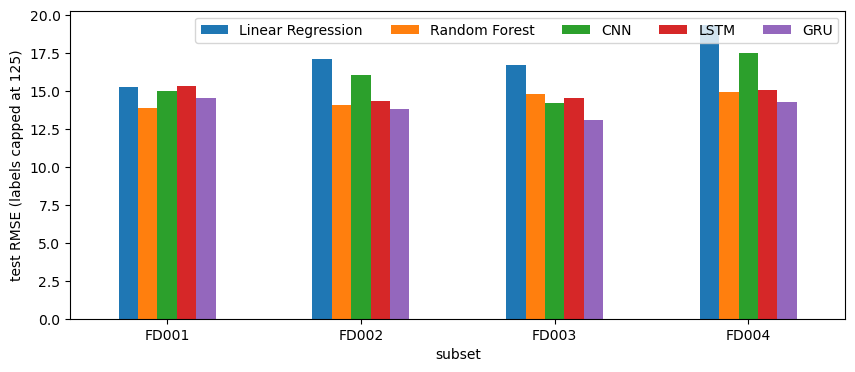

In [9]:
rmse = results.pivot(index="subset", columns="model", values="RMSE")
rmse[["Linear Regression", "Random Forest", "CNN", "LSTM", "GRU"]].plot.bar(figsize=(10, 4))
plt.ylabel("test RMSE (labels capped at 125)")
plt.xticks(rotation=0)
plt.legend(ncol=5)
plt.show()

## Conclusions

- **GRU is the best model on FD002, FD003 and FD004** (RMSE 13.84 / 13.07 / 14.26) and also has the best NASA score on those three.
- **Random Forest is still best on FD001** (13.90 vs 14.55 for GRU). FD001 is the simplest subset (one condition, one fault), so 4 summary features per sensor are enough there.
- Deep models help most on the **harder subsets**: on FD003 (two fault modes) GRU beats Random Forest by 1.7 RMSE, and its NASA score is much better (387 vs 681), so it makes fewer late predictions.
- **CNN is the weakest deep model**, especially on FD004 (17.53). LSTM sits between CNN and GRU.
- The gain over Random Forest is modest (at most about 1.7 RMSE). Deep learning is not automatically better here, which is why the baselines were important.

**Limitations**
- Each model was trained once with one random seed. Re-running with a different seed can move the RMSE by about ±1, so small differences (e.g. LSTM vs CNN on FD001) are not reliable.
- No hyperparameter tuning yet (layer sizes, learning rate, window length are fixed).
- Deep models were trained on 80% of the engines (20% used for early stopping), while the baselines used 100%.